# 08 · Engenharia de dados: duplicatas, vazamento, rótulos ruins e dados sintéticos

> **Capítulo 8 do livro:** *Dataset Engineering*.
> Nos capítulos anteriores o dado apareceu como pano de fundo: o conjunto de avaliação (cap. 4), os manuais do RAG (cap. 6), os exemplos do ajuste (cap. 7). Aqui ele é o assunto. Em muitos projetos, **melhorar o dado rende mais que trocar o modelo**.

**Objetivo:** pegar uma pilha de relatos de parada "como vêm da fábrica" e transformá-la num conjunto confiável, medindo cada decisão: o que a deduplicação remove, quanto o **vazamento** infla um resultado, quanto o **rótulo errado** custa, e quando **dado sintético** ajuda e quando só parece ajudar.

## Antes de começar

- **Você precisa saber:** os notebooks 04 (avaliação, intervalos) e 07 (cobertura dos exemplos de ajuste).
- **Dados:** 100 % sintéticos, gerados em `aiind/datasets.py`, com os defeitos que relatos reais têm: repetidos, quase repetidos, lixo, erros de digitação, rótulo errado e cobertura desigual. **Não há dado real de planta aqui.**
- **Modelo:** um classificador simples (Naive Bayes sobre palavras) que treina em milissegundos. Ele serve para **medir o efeito do dado**; o ponto não é o modelo.
- **Tempo:** 60 minutos.

## Mapa do notebook

1. O que chega da fábrica
2. Duplicatas: exatas, normalizadas e quase iguais
3. Limpeza por regras
4. Vazamento: o teste que mente
5. Rótulos: concordância e ruído
6. Qualidade contra quantidade
7. Cobertura e dados sintéticos
8. O pipeline completo e o cartão do conjunto

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. O que chega da fábrica

Geramos 400 relatos distintos e deixamos o "mundo real" estragá-los: operadores copiam e colam (repetidas), reenviam com pequenas mudanças (quase repetidas), digitam errado, escrevem em maiúsculas, deixam entradas inúteis ("teste", "ok"), e às vezes **rotulam a família da falha errada**, quase sempre trocando por uma família parecida (calor por vazamento, ruído por travamento).

In [2]:
from aiind.datasets import *
from aiind.evaluation import cohen_kappa
from collections import Counter
import numpy as np, random
R = raw_reports(400, seed=0)
print(f"{len(R)} registros;", dict(Counter(r.kind for r in R)))
print(f"rótulos diferentes do real: {sum(r.label != r.true for r in R if r.kind != 'junk')} de {sum(r.kind != 'junk' for r in R)}")
for r in R[:8]:
    print(f"  [{r.kind:8s}] {r.text!r:70s} -> {r.label}")

512 registros; {'near': 52, 'original': 400, 'junk': 12, 'exact': 48}
rótulos diferentes do real: 49 de 500
  [near    ] 'praada na prensa matriz travou.'                                      -> travamento
  [original] 'ESTEIRA PARADA CORREIA COM RUÍDO'                                     -> ruído
  [near    ] 'obs: esteira parou correia preso linha 1'                             -> travamento
  [original] 'parada na esteira correia barulho lote 2403'                          -> ruído
  [near    ] 'turno b - prensa parada pingando mangueira pressão 5 bar;'            -> vazamento
  [original] 'parada  na esteira rolamento zunindo desde 23h42.'                    -> ruído
  [original] 'ref. matriz travou na prensa lote 4793 ..'                            -> travamento
  [original] 'mangueira pingando na prensa etmp 73 graus'                           -> vazamento


### Pare e preveja

Se 400 relatos foram gerados e 12 são lixo, quantos relatos **distintos** existem? Quantos sobram depois de remover as repetidas exatas? E depois de remover as quase repetidas?

## 2. Duplicatas: exatas, normalizadas e quase iguais

Três níveis, do mais barato ao mais caro:

1. **Exata:** o texto é idêntico. Um `set` resolve.
2. **Normalizada:** igual depois de minúsculas, sem acento, sem pontuação, sem espaço duplo.
3. **Quase igual:** diferem por erro de digitação, prefixo, ordem. Aqui usamos **similaridade de Jaccard** entre os conjuntos de trechos de 4 caracteres, e **MinHash** (uma assinatura curta que estima o Jaccard) com **LSH** (agrupa por faixas da assinatura) para não comparar todos os pares.

relatos distintos de verdade: 400
registros: 512 -> exatas removidas: 453 -> normalizadas: 428 -> quase iguais (0,8): 398


erro médio da estimativa: 0.019


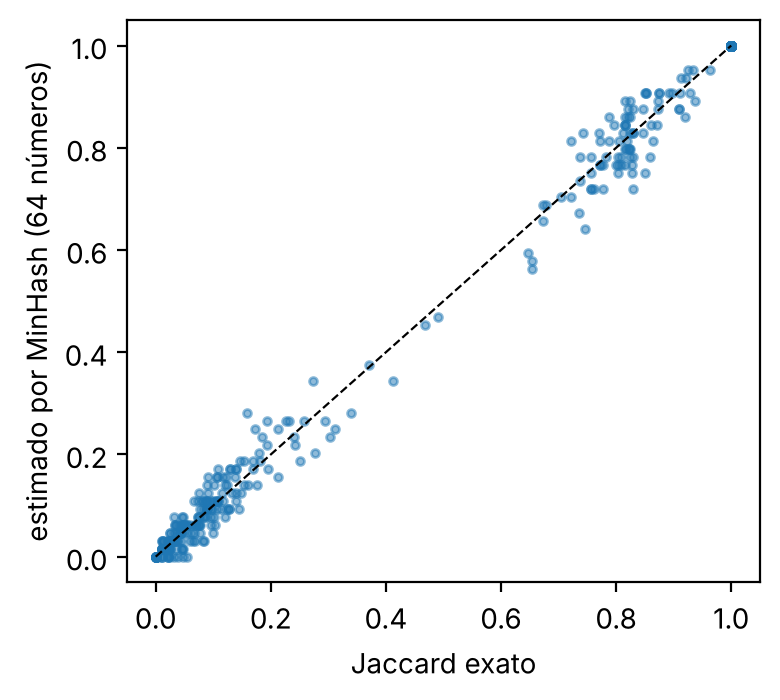

In [3]:
n_dist = len({r.group for r in R if r.kind != "junk"})
print(f"relatos distintos de verdade: {n_dist}")
print(f"registros: {len(R)} -> exatas removidas: {len(dedup_exact(R))} -> normalizadas: {len(dedup_normalized(R))} -> quase iguais (0,8): {len(dedup_near(R, 0.8))}")

# MinHash estima o Jaccard com poucas dezenas de números
rng = random.Random(7); xs, ys = [], []
base = [r for r in R if r.kind == "original"][:120]
for _ in range(400):
    a, b = rng.sample(base, 2)
    if rng.random() < .5:
        b = Rec(0, corrupt(a.text.lower(), rng), a.label, a.true, a.group)
    sa, sb = shingles(a.text), shingles(b.text)
    xs.append(jaccard(sa, sb)); ys.append(est_jaccard(minhash(sa, 64), minhash(sb, 64)))
fig, ax = plt.subplots(figsize=(4, 3.6)); ax.scatter(xs, ys, s=8, alpha=.5); ax.plot([0, 1], [0, 1], "k--", lw=.8)
ax.set_xlabel("Jaccard exato"); ax.set_ylabel("estimado por MinHash (64 números)"); plt.tight_layout()
print(f"erro médio da estimativa: {np.mean(np.abs(np.array(xs) - np.array(ys))):.3f}")

O limiar é uma decisão, não um padrão. Mede-se contra a verdade conhecida: **quantas repetidas ficam de fora do grupo** (recall) e **quantos grupos juntaram relatos distintos** (impuros):

In [4]:
from collections import defaultdict
print(f"{'limiar':>7s} {'grupos':>7s} {'impuros':>8s} {'recall das repetidas':>22s}")
for th in (0.5, 0.6, 0.7, 0.8, 0.9):
    cl = near_clusters(R, th); d = defaultdict(set)
    for r, c in zip(R, cl): d[c].add(r.group)
    og = {r.group: cl[i] for i, r in enumerate(R) if r.kind == "original"}
    dups = [i for i, r in enumerate(R) if r.kind in ("exact", "near")]
    rec = np.mean([cl[i] == og[R[i].group] for i in dups])
    print(f"{th:7.1f} {len(set(cl)):7d} {sum(len([g for g in v if g >= 0]) > 1 for v in d.values()):8d} {rec:21.0%}")

 limiar  grupos  impuros   recall das repetidas
    0.5     186       58                  100%
    0.6     287       58                   98%


    0.7     363       30                   97%
    0.8     398       13                   90%
    0.9     423        4                   77%


- **Limiar baixo (0,5)** pega todas as repetidas, mas **funde relatos diferentes** (impuros: eram falhas distintas na mesma máquina, com texto parecido).
- **Limiar alto (0,9)** quase não funde nada, mas **deixa escapar** parte das repetidas.
- Em torno de **0,8** o número de grupos fica perto dos 400 reais. O ponto certo depende do custo: perder um relato distinto é pior que manter uma repetida? Para **treino**, repetida a mais pesa pouco; para **teste**, repetida entre treino e teste **mente** (próxima seção).

**Atenção a um detalhe de domínio:** num log de paradas, o mesmo texto repetido pode ser **o mesmo evento copiado** ou **a mesma falha acontecendo de novo**. Para treinar, deduplica-se; para **análise** (Pareto de paradas), a frequência é a informação. Guarde a contagem antes de remover.

## 3. Limpeza por regras

Antes de qualquer modelo, regras simples e **auditáveis**: descartar texto vazio ou curto demais, e relato sem nenhuma palavra de falha conhecida. Cada regra reporta **quanto removeu**, porque uma regra que remove demais é um bug.

In [5]:
base_ = dedup_near(R, 0.8)
limpo, descartados = clean_rules(base_)
print("depois da deduplicação:", len(base_), "| depois das regras:", len(limpo), "| descartados:", descartados)
print("lixo que sobrou:", sum(r.kind == "junk" for r in limpo), "| registros bons descartados por engano:", sum(r.kind != "junk" for r in base_) - sum(r.kind != "junk" for r in limpo))

depois da deduplicação: 398 | depois das regras: 370 | descartados: {'vazio ou curto': 4, 'sem palavra de falha': 24}
lixo que sobrou: 0 | registros bons descartados por engano: 24


Todo o lixo saiu, mas **24 relatos bons caíram junto**: a regra "tem palavra de falha" é exata, e esses relatos tinham erro de digitação justamente na palavra do sintoma ("praada", "etmp"). Regra rígida demais vira perda de dado. As saídas: comparar por **similaridade aproximada** em vez de igualdade, ou mandar para **revisão** os descartados por essa regra em vez de jogá-los fora. Sempre olhe uma amostra do que a regra removeu.

## 4. Vazamento: o teste que mente

**Vazamento** acontece quando algo do conjunto de teste já está no treino. O modelo é "avaliado" em coisas que decorou, e o resultado parece ótimo. O caso mais comum: repetidas e quase repetidas caem **dos dois lados** de uma divisão aleatória.

Comparamos duas divisões, com 100 % de repetição (um log com muito copiar e colar): **aleatória** e **por grupo** (todas as versões de um mesmo relato vão para o mesmo lado). O modelo é um que **memoriza** (1 vizinho mais próximo), e medimos também num conjunto externo, limpo.

 repetição |  ALEATÓRIA: teste interno  externo  vazou |  POR GRUPO: interno  externo  vazou
        0% |                       92%      92%     4% |                 92%      91%     4%
       25% |                       93%      91%    29% |                 93%      91%     3%
       60% |                       97%      91%    45% |                 93%      91%     3%
      100% |                       98%      92%    63% |                 92%      91%     3%


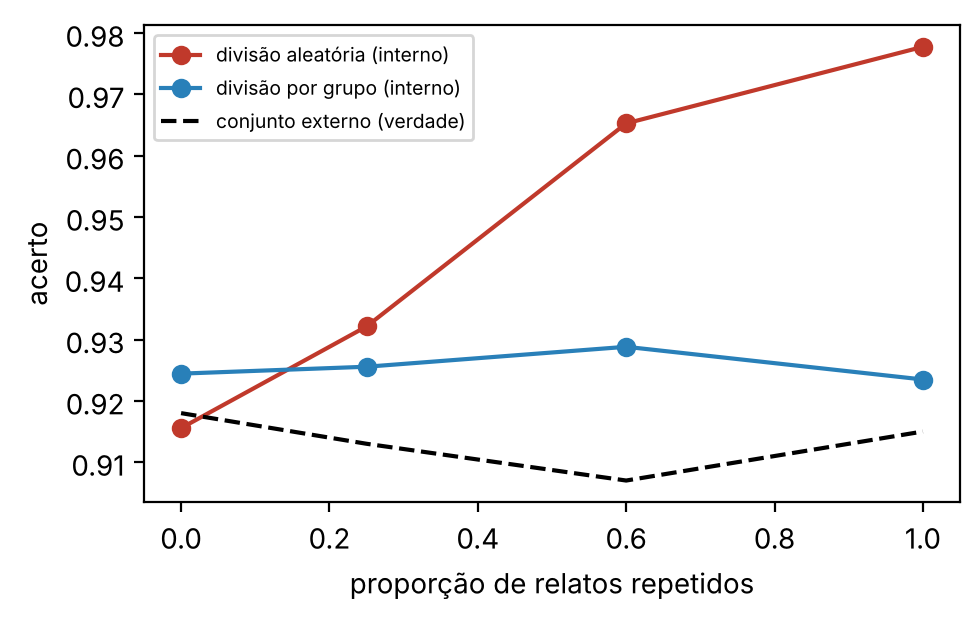

In [6]:
tt, ty = held_out(600)
rows = []
for dup in (0.0, 0.25, 0.6, 1.0):
    res = []
    for seed in range(5):
        Rd = [r for r in raw_reports(300, seed, dup_rate=dup, label_noise=0.0) if r.kind != "junk"]
        row = []
        for sp in (split_random, split_by_group):
            a, b = sp(Rd, 0.3, seed)
            m = Memorizer().fit([r.text for r in a], [r.label for r in a])
            row += [m.accuracy([r.text for r in b], [r.label for r in b]), m.accuracy(tt[:200], ty[:200]), leakage(a, b, 0.8)]
        res.append(row)
    rows.append(np.mean(res, 0))
print(f"{'repetição':>10s} | {'ALEATÓRIA: teste interno':>25s} {'externo':>8s} {'vazou':>6s} | {'POR GRUPO: interno':>19s} {'externo':>8s} {'vazou':>6s}")
for dup, r in zip((0.0, 0.25, 0.6, 1.0), rows):
    print(f"{dup:10.0%} | {r[0]:25.0%} {r[1]:8.0%} {r[2]:6.0%} | {r[3]:19.0%} {r[4]:8.0%} {r[5]:6.0%}")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot([0, .25, .6, 1], [r[0] for r in rows], "o-", c="#c0392b", label="divisão aleatória (interno)")
ax.plot([0, .25, .6, 1], [r[3] for r in rows], "o-", c="#2980b9", label="divisão por grupo (interno)")
ax.plot([0, .25, .6, 1], [r[1] for r in rows], "k--", label="conjunto externo (verdade)")
ax.set_xlabel("proporção de relatos repetidos"); ax.set_ylabel("acerto"); ax.legend(fontsize=7); plt.tight_layout()

- Na divisão **aleatória**, o acerto interno **sobe com a repetição** (de 92 % para 98 %), enquanto o desempenho **verdadeiro** (conjunto externo) fica parado em ~91 %. A diferença é o vazamento: 63 % do teste tinha um parente no treino.
- Na divisão **por grupo**, o número interno fica honesto, perto do externo.

A regra prática: **primeiro deduplique, depois divida, e divida por grupo** (por máquina, por turno, por dia ou por relato original, o que representar "a mesma coisa"). Em dados de série temporal, divida por **tempo**: treinar com o futuro e testar no passado é vazamento também.

## 5. Rótulos: concordância e ruído

Quem rotula erra, principalmente onde a definição é ambígua (aquecer por vazamento de óleo é "calor" ou "vazamento"?). Duas medidas:

- **Concordância entre anotadores** (kappa, já usado no notebook 03): se dois humanos discordam muito, a tarefa ou o guia de anotação está mal definido.
- **Efeito do ruído no modelo** e **quanto dá para recuperar** com uma revisão dirigida.

In [7]:
verdade = [r.true for r in raw_reports(300, 0, dup_rate=0, junk_rate=0, label_noise=0)]
print("erro individual -> concordância entre dois anotadores / kappa")
for e in (0.05, 0.1, 0.2, 0.3):
    a, b = annotate(verdade, 1, e), annotate(verdade, 2, e)
    print(f"   {e:4.0%}   ->   {np.mean([x == y for x, y in zip(a, b)]):.0%} / {cohen_kappa(a, b):.2f}")

erro individual -> concordância entre dois anotadores / kappa
     5%   ->   88% / 0.85
    10%   ->   82% / 0.77
    20%   ->   70% / 0.62
    30%   ->   56% / 0.44


Agora o efeito no modelo, e a **revisão dirigida**: treina-se com validação cruzada, e marca-se para **revisão humana** o relato cujo rótulo escrito recebe probabilidade baixa do modelo que não o viu. Não se corrige sozinho: o modelo só **aponta onde olhar**.

 ruído   acerto  sem os marcados  precisão da marcação  cobertura dos errados


    0%    98.4%            98.1%                    0%                      -


   10%    94.6%            96.5%                   83%                    87%

   20%    90.8%            92.2%                   85%                    80%


   30%    85.3%            87.0%                   82%                    69%


   40%    75.0%            77.2%                   74%                    58%


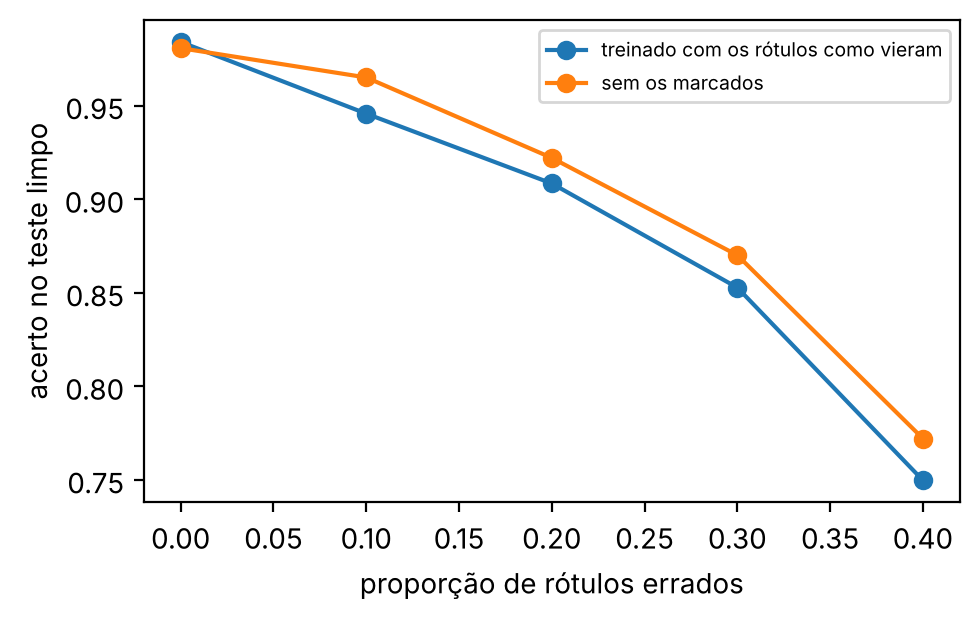

In [8]:
print(f"{'ruído':>6s} {'acerto':>8s} {'sem os marcados':>16s} {'precisão da marcação':>21s} {'cobertura dos errados':>22s}")
curva = []
for ln in (0, 0.1, 0.2, 0.3, 0.4):
    acc, accf, pr, rc = [], [], [], []
    for seed in range(5):
        Rl = raw_reports(300, seed, dup_rate=0, junk_rate=0, label_noise=ln)
        T = [r.text for r in Rl]; L = [r.label for r in Rl]
        acc.append(NB().fit(T, L).accuracy(tt, ty))
        fl = set(flag_suspects(T, L, thr=0.3)); keep = [i for i in range(len(Rl)) if i not in fl]
        accf.append(NB().fit([T[i] for i in keep], [L[i] for i in keep]).accuracy(tt, ty))
        wrong = {i for i, r in enumerate(Rl) if r.label != r.true}
        if fl: pr.append(len(fl & wrong) / len(fl))
        if wrong: rc.append(len(fl & wrong) / len(wrong))
    curva.append((ln, np.mean(acc), np.mean(accf)))
    fmt = lambda v: f"{np.mean(v):.0%}" if v else "-"
    print(f"{ln:6.0%} {np.mean(acc):8.1%} {np.mean(accf):16.1%} {fmt(pr):>21s} {fmt(rc):>22s}")
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot([c[0] for c in curva], [c[1] for c in curva], "o-", label="treinado com os rótulos como vieram"); ax.plot([c[0] for c in curva], [c[2] for c in curva], "o-", label="sem os marcados")
ax.set_xlabel("proporção de rótulos errados"); ax.set_ylabel("acerto no teste limpo"); ax.legend(fontsize=7); plt.tight_layout()

- O ruído **corrói o acerto de forma regular**: 10 % de rótulos errados custam uns 4 pontos; 40 %, mais de 20.
- A marcação **acerta 74 a 85 % das vezes** que aponta um rótulo, e encontra de **58 a 87 %** dos errados. Revisar só os marcados é muito mais barato que revisar tudo.
- Remover os marcados **ajuda pouco** (1 a 2 pontos): o modelo simples já tolera ruído razoavelmente. O valor está em **corrigir** os marcados com um humano (ou um especialista do chão de fábrica), não em descartá-los. E o **conjunto de avaliação** merece revisão total, porque o ruído nele distorce todas as comparações.
- O caso perigoso é o ruído **sistemático** (sempre trocar "calor" por "vazamento"). Aqui ele é assim, de propósito, e mesmo assim a marcação funciona; mas se o anotador erra **sempre do mesmo jeito**, o modelo aprende o erro como regra.

## 6. Qualidade contra quantidade

A pergunta de orçamento: vale mais **mais exemplos ruidosos** ou **poucos exemplos limpos**? Comparamos 30 exemplos limpos com conjuntos ruidosos (30 % de rótulos errados) de tamanhos crescentes.

   30 ruidosos: 56%   | 30 limpos: 78%
   60 ruidosos: 69%   | 30 limpos: 78%
  120 ruidosos: 76%   | 30 limpos: 78%
  300 ruidosos: 85%   | 30 limpos: 78%
 1000 ruidosos: 92%   | 30 limpos: 78%


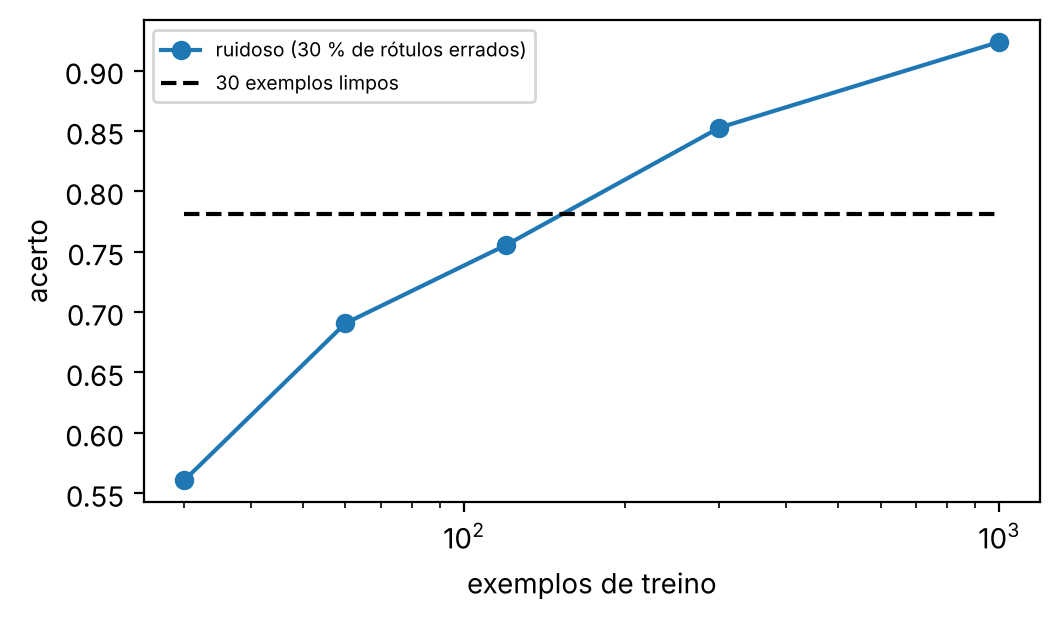

In [9]:
ns = [30, 60, 120, 300, 1000]; ruidoso, limpo30 = [], []
for n in ns:
    a, b = [], []
    for seed in range(5):
        Rn = raw_reports(n, seed, dup_rate=0, junk_rate=0, label_noise=0.3); Rc = raw_reports(30, seed + 50, dup_rate=0, junk_rate=0, label_noise=0.0)
        a.append(NB().fit([r.text for r in Rn], [r.label for r in Rn]).accuracy(tt, ty)); b.append(NB().fit([r.text for r in Rc], [r.label for r in Rc]).accuracy(tt, ty))
    ruidoso.append(np.mean(a)); limpo30.append(np.mean(b))
fig, ax = plt.subplots(figsize=(5.4, 3.2)); ax.plot(ns, ruidoso, "o-", label="ruidoso (30 % de rótulos errados)"); ax.plot(ns, limpo30, "k--", label="30 exemplos limpos")
ax.set_xscale("log"); ax.set_xlabel("exemplos de treino"); ax.set_ylabel("acerto"); ax.legend(fontsize=7); plt.tight_layout()
for n, a, b in zip(ns, ruidoso, limpo30): print(f"{n:5d} ruidosos: {a:.0%}   | 30 limpos: {b:.0%}")

**30 exemplos limpos (78 %) valem uns 120 ruidosos (76 %)** neste problema. O ruído se compensa com volume, mas o volume tem custo de coleta e revisão; a conta certa é a do **custo por exemplo corrigido**. Isso não é uma regra universal: com modelos grandes e ruído aleatório, o volume compensa mais; com ruído sistemático, compensa menos.

## 7. Cobertura e dados sintéticos

No capítulo 7, o ajuste com exemplos que só mostravam metade dos sinônimos não generalizou. O problema é de **cobertura**: o conjunto não tem exemplos de parte das situações. Veja o mapa (família × palavra do sintoma) de um conjunto coletado com só 2 dos 4 sinônimos por família:

células com zero exemplos: 10 de 20


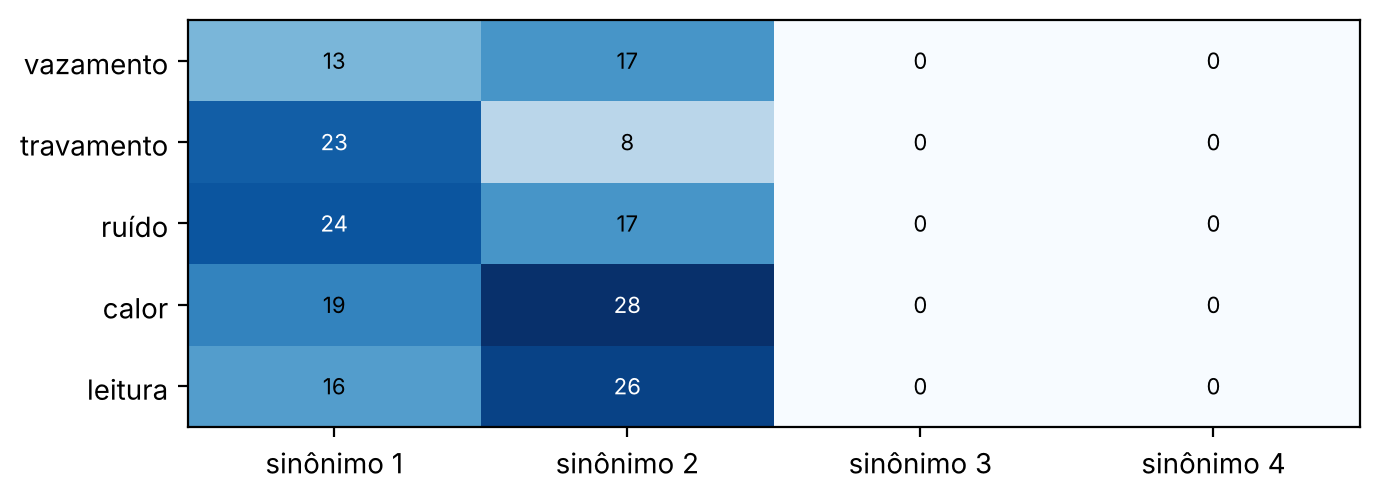

In [10]:
Rcov = raw_reports(200, 3, dup_rate=0, junk_rate=0, label_noise=0, n_symptoms=2)
cov = coverage_table(Rcov); fams = list(FAMILIES)
fig, ax = plt.subplots(figsize=(7, 2.6)); M = np.array([[cov[(f, s)] for s in FAMILIES[f]["sintomas"]] for f in fams])
im = ax.imshow(M, cmap="Blues", aspect="auto"); ax.set_yticks(range(5), fams); ax.set_xticks(range(4), ["sinônimo 1", "sinônimo 2", "sinônimo 3", "sinônimo 4"])
for i in range(5):
    for j in range(4): ax.text(j, i, M[i, j], ha="center", va="center", fontsize=8, color="w" if M[i, j] > 20 else "k")
plt.tight_layout()
print("células com zero exemplos:", int((M == 0).sum()), "de", M.size)

Os zeros são as **lacunas**. **Dados sintéticos** preenchem lacunas, mas com cuidado. Quatro estratégias, com 40 relatos reais de cobertura parcial (média de 6 sementes, teste com todos os sinônimos):

1. **Só real.**
2. **+ sintético com os mesmos 2 sinônimos** (mais volume, sem cobertura nova).
3. **+ sintético com os 4 sinônimos** (cobre as lacunas).
4. **+ sintético com os 4 sinônimos, mas peças e sintomas combinados ao acaso** (falhas inventadas que não existem, como um sensor "vazando").
5. **+ sintético em estilo de redação diferente do real.**

In [11]:
def acc_sint(fn, seeds=6):
    a = []
    for seed in range(seeds):
        Rr = raw_reports(40, seed, dup_rate=0, junk_rate=0, label_noise=0.0, n_symptoms=2); S = fn(seed)
        a.append(NB().fit([r.text for r in Rr] + [t for t, _ in S], [r.label for r in Rr] + [f for _, f in S]).accuracy(tt, ty))
    return np.mean(a), np.std(a)
estrategias = {"1. só real": lambda s: [], "2. + sintético, 2 sinônimos": lambda s: synth(200, s, 2), "3. + sintético, 4 sinônimos": lambda s: synth(200, s, 4),
               "4. + 4 sinônimos, pareamento aleatório": lambda s: synth(200, s, 4, pairing="random"), "5. + 4 sinônimos, outro estilo": lambda s: synth(200, s, 4, "B")}
for nome, fn in estrategias.items():
    m, sd = acc_sint(fn); print(f"{nome:42s} {m:.1%} ±{sd:.1%}")

1. só real                                 74.8% ±3.1%
2. + sintético, 2 sinônimos                86.6% ±1.1%


3. + sintético, 4 sinônimos                97.2% ±0.7%
4. + 4 sinônimos, pareamento aleatório     91.8% ±3.0%


5. + 4 sinônimos, outro estilo             96.6% ±0.8%


- **Cobertura nova é o que mais ajuda** (de 75 % para 97 %). Mais volume sem cobertura ajuda pouco (87 %).
- **Falhas inventadas** (pareamento aleatório) **custam** alguns pontos e **aumentam a variação** entre execuções (92 % ±3): o dado sintético ruim não é neutro.
- A diferença de **estilo de redação** quase não importou aqui porque o classificador olha palavras; para um modelo de linguagem que aprende o estilo, importaria mais. Meça no seu caso.

### O limite do sintético: o que o autor não sabia

Todo dado sintético gerado por regras carrega **o que quem escreveu as regras conhecia**. Se aparecem na fábrica palavras que ninguém listou ("gotejando", "engripado", "rangendo"), o sintético não tem como cobri-las. Testamos com um conjunto onde cada palavra de sintoma foi trocada por uma fora da lista:

In [12]:
extra = {"vazamento": ["gotejando", "porejando"], "travamento": ["engripado", "agarrado"], "ruído": ["rangendo", "chiando"], "calor": ["fervendo", "queimando"], "leitura": ["zerada", "congelada"]}
rr = random.Random(5)
def trocar(t, f):
    for s in FAMILIES[f]["sintomas"]:
        if s in t: return t.replace(s, rr.choice(extra[f]))
    return t
tt2 = [trocar(t, f) for t, f in zip(tt, ty)]
Rr = raw_reports(40, 1, dup_rate=0, junk_rate=0, label_noise=0.0, n_symptoms=2)
for nome, S in {"só real": [], "real + sintético (4 sinônimos)": synth(300, 1)}.items():
    m = NB().fit([r.text for r in Rr] + [t for t, _ in S], [r.label for r in Rr] + [f for _, f in S])
    print(f"{nome:34s} palavras da lista: {m.accuracy(tt, ty):.0%}   palavras novas: {m.accuracy(tt2, ty):.0%}")
d_real = diversity([r.text for r in raw_reports(200, 0, dup_rate=0, junk_rate=0)]); d_syn = diversity([t for t, _ in synth(200, 0)])
print("\ndiversidade  real:", {k: round(v, 2) for k, v in d_real.items()}, "\n             sintético:", {k: round(v, 2) for k, v in d_syn.items()})

só real                            palavras da lista: 70%   palavras novas: 63%
real + sintético (4 sinônimos)     palavras da lista: 98%   palavras novas: 80%

diversidade  real: {'textos distintos': 1.0, 'bigramas distintos': 0.41, 'vocabulário': 193} 
             sintético: {'textos distintos': 0.81, 'bigramas distintos': 0.26, 'vocabulário': 55}


O sintético passou de 98 % para ~80 % nas palavras novas: **o ganho é real, mas é um ganho dentro do que o autor imaginou**. Por isso:

- **Teste sempre com dado real** e, quando possível, com **palavras fora das listas** (conjunto de "desconhecidos desconhecidos").
- Meça a **diversidade** do sintético (textos distintos, bigramas distintos, vocabulário). O sintético gerado aqui tem vocabulário de 55 palavras contra 193 do real: é **mais pobre**, e treinar só com ele ensina um mundo menor.
- Com **geração por modelo de linguagem**, o raciocínio é o mesmo, com um risco extra: o modelo repete o próprio estilo e vieses (conhecido como colapso quando se treina modelos sobre saídas de modelos). Filtre por regra (a peça combina com a falha?), deduplique e **verifique uma amostra à mão**.

## 8. O pipeline completo e o cartão do conjunto

A ordem importa: **normalizar e deduplicar → limpar → dividir por grupo → revisar rótulos → (só no treino) acrescentar sintéticos**. O sintético nunca entra no teste.

In [13]:
def pipeline(recs, seed=0):
    log = {"bruto": len(recs)}
    r = dedup_near(recs, 0.8); log["após deduplicação"] = len(r)
    r, drop = clean_rules(r); log["após regras"] = len(r)
    tr, te = split_by_group(r, 0.3, seed)
    log["treino"], log["teste"] = len(tr), len(te)
    fl = flag_suspects([x.text for x in tr], [x.label for x in tr], thr=0.3); log["rótulos a revisar (treino)"] = len(fl)
    return tr, te, fl, log
Rb = raw_reports(600, 11, dup_rate=0.5, junk_rate=0.03, label_noise=0.15)
tr, te, fl, log = pipeline(Rb)
print(log)
corrigido = [Rec(r.id, r.text, r.true if i in set(fl) else r.label, r.true, r.group, r.kind) for i, r in enumerate(tr)]   # o humano revisou os marcados
for nome, conj in {"bruto (sem pipeline)": Rb, "pipeline, sem revisão": tr, "pipeline + revisão dos marcados": corrigido}.items():
    c = [x for x in conj if x.kind != "junk"] if nome.startswith("bruto") else conj
    print(f"{nome:34s} {len(c):4d} exemplos  acerto no externo: {NB().fit([x.text for x in c], [x.label for x in c]).accuracy(tt, ty):.1%}")
print(f"\nrótulos errados que restam depois da revisão: {sum(x.label != x.true for x in corrigido)} de {len(corrigido)}")

{'bruto': 918, 'após deduplicação': 611, 'após regras': 571, 'treino': 399, 'teste': 172, 'rótulos a revisar (treino)': 53}
bruto (sem pipeline)                900 exemplos  acerto no externo: 96.5%
pipeline, sem revisão               399 exemplos  acerto no externo: 92.8%
pipeline + revisão dos marcados     399 exemplos  acerto no externo: 96.7%

rótulos errados que restam depois da revisão: 7 de 399


Leia com cuidado: o bruto treina com 900 registros (metade repetidos, 15 % com rótulo errado) e o pipeline com 399, porque as repetidas saíram e 30 % foram reservados para teste. Por isso o pipeline sem revisão fica abaixo (92,8 contra 96,5 %); com a revisão dos 53 marcados ele **empata com menos da metade dos dados** (96,7 %), e restam 7 rótulos errados em 399, contra cerca de 15 % antes. O mais importante não aparece nessa coluna: **você consegue afirmar** que o teste não tem vazamento e que cada passo tem número. Anote isso num **cartão do conjunto** (uma página, versionada junto com o dado):

- **Origem** (sistema, período, quem coletou) e **o que foi excluído** (e por quê).
- **Tamanho** antes e depois de cada passo.
- **Limiar de duplicata** e como foi escolhido.
- **Divisão** (por quê, por qual grupo) e **vazamento medido**.
- **Qualidade dos rótulos**: kappa, proporção revisada, ruído estimado.
- **Cobertura** e **lacunas conhecidas**.
- **Parte sintética**, como foi gerada, e como foi validada.
- **Privacidade**: o que foi anonimizado (nomes de operador, números de lote que identificam cliente).

## Erros comuns

- **Dividir antes de deduplicar**, ou dividir ao acaso quando há repetição.
- **Dedup sem guardar a contagem**, e perder a frequência que a análise precisava.
- **Limiar de similaridade copiado de um tutorial**, sem medir fusões e escapes.
- **Rótulos nunca revisados** e **conjunto de avaliação com rótulo ruidoso**.
- **Sintético no teste**, ou sintético sem comparar com o real.
- **Confundir volume com cobertura**: mil exemplos de metade das situações.
- **Tratar o dado como fixo**: ele muda (novas máquinas, novas palavras), então precisa de **monitoramento** e de uma rotina de atualização.
- **Esquecer privacidade**: texto livre de operador contém nomes e identificadores.

## Confira o que ficou

**1. Por que remover duplicatas antes de dividir treino e teste?**

<details><summary>Ver resposta</summary>

Porque repetidas dos dois lados deixam o modelo ser testado em algo que já viu, inflando o resultado (vazamento).

</details>

**2. O que o MinHash com LSH resolve?**

<details><summary>Ver resposta</summary>

Estimar a similaridade (Jaccard) com assinaturas curtas e comparar só candidatos prováveis, sem calcular todos os pares.

</details>

**3. O limiar de similaridade baixo ou alto, qual o risco de cada um?**

<details><summary>Ver resposta</summary>

Baixo funde relatos distintos; alto deixa escapar repetidas. Escolhe-se medindo contra uma verdade conhecida e pelo custo de cada erro.

</details>

**4. Por que um log de paradas pode ter 'duplicatas' que não devem sumir?**

<details><summary>Ver resposta</summary>

O mesmo texto pode ser a mesma falha acontecendo de novo; a frequência é informação para análise. Deduplica-se para treino, guardando a contagem.

</details>

**5. Para que serve marcar rótulos suspeitos com validação cruzada?**

<details><summary>Ver resposta</summary>

Para direcionar a revisão humana aos poucos relatos mais prováveis de estarem errados, em vez de revisar tudo.

</details>

**6. Por que dado sintético não substitui dado real?**

<details><summary>Ver resposta</summary>

Só contém o que quem o gerou conhecia, é menos diverso, e pode incluir combinações que não existem. Deve ser validado e nunca entrar no teste.

</details>

**7. O que o cartão do conjunto registra?**

<details><summary>Ver resposta</summary>

Origem, exclusões, tamanhos por passo, limiar, divisão, qualidade dos rótulos, cobertura, parte sintética e privacidade.

</details>

## Exercícios

1. **Limiar por custo:** defina um custo para "perder um relato distinto" e outro para "manter uma repetida" e escolha o limiar que minimiza o custo total.
2. **Divisão temporal:** acrescente uma data a cada relato e compare a divisão por tempo com a por grupo. Quando elas diferem?
3. **Rótulo sistemático:** faça o anotador trocar sempre "calor" por "vazamento" (e não ao acaso). A marcação por validação cruzada ainda encontra os erros?
4. **Anonimização:** acrescente nomes de operador ao texto e escreva uma regra que os remova. Que parte do texto sobra de útil?
5. **Sintético com filtro:** gere sintéticos sem restrição de peça e escreva uma regra que descarta os que combinam peça e falha de forma impossível. Quanto do ganho volta?
6. **Quanto sintético:** varie a proporção de sintético (10 %, 50 %, 90 %, 99 %) e meça no conjunto real. Há um ponto em que atrapalha?
7. **Cartão do conjunto:** preencha o cartão para o pipeline da seção 8 com os números reais.

## Glossário

- **Deduplicação:** remover relatos repetidos (exatos, normalizados ou quase iguais).
- **Jaccard:** razão entre a interseção e a união de dois conjuntos; mede quanto se parecem.
- **MinHash:** assinatura curta que estima o Jaccard.
- **LSH:** agrupamento por faixas da assinatura, para achar candidatos sem comparar todos os pares.
- **Vazamento:** informação do teste presente no treino.
- **Divisão por grupo:** manter todas as versões de um mesmo item do mesmo lado.
- **Kappa:** concordância entre anotadores descontada a do acaso.
- **Ruído de rótulo:** rótulos errados no conjunto.
- **Cobertura:** quanto das situações possíveis o conjunto representa.
- **Dado sintético:** gerado por regras ou por um modelo, não observado.
- **Cartão do conjunto:** documento curto que descreve origem, limpeza e limites do dado.

## Próximo passo

**Notebook 09, capítulo 9 (Inference Optimization):** o que fazer depois que o modelo existe: latência, vazão, custo por pedido, cache, lotes, decodificação e as trocas entre qualidade e velocidade, com conta de borda (no equipamento) contra nuvem.